# RQ0a: did US cities stall, or did their metros? (Plan 2)

Spec: `docs/superpowers/specs/2026-10-18-rq0a-city-vs-metro-design.md`. Each headline metro (one
holding a 1950 top-100 city; "the city" is its largest 1950 city) is classed in 1950–70, 1970–90
and 1990–2020 by whether its city and its metro kept up with US population growth (main bar:
half the US rate). Three questions get answers from rules fixed before anything was computed
(spec §4.3); every answer has a 90% range from resampling headline metros (999 draws, seed 0)
and is "fragile" if a check that applies to it disagrees. Findings describe population, not
moves (D-29).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from us_housing_crisis_analysis import geography
from us_housing_crisis_analysis.config import PROCESSED_DATA_DIR, RQ0A_PERIODS, TABLES_DIR
from us_housing_crisis_analysis.modeling import city_metro as cm
from us_housing_crisis_analysis.plots import MUTED, SERIES_COLORS, apply_style, save_figure, spread_labels

apply_style()
panel = pd.read_parquet(PROCESSED_DATA_DIR / "us_city_metro.parquet")
states = pd.read_parquet(PROCESSED_DATA_DIR / "us_state_longrun.parquet")
consolidations = geography.load_consolidations()
US = cm.us_growth(states, geography.state_divisions().index)
label = {s: f"{s}–{e}" for s, e in RQ0A_PERIODS}
head = panel[panel.headline]
print(f"{head.geo_id.nunique()} headline metros; US growth by period:",
      {label[s]: f"{g:+.1%}" for (s, e), g in US.items()})

2026-10-19 15:38:36.651 | INFO     | us_housing_crisis_analysis.config:<module>:11 - PROJ_ROOT path is: /Users/lrubin/Documents/code/US Housing Crisis Analysis


81 headline metros; US growth by period: {'1950–1970': '+34.3%', '1970–1990': '+22.4%', '1990–2020': '+33.3%'}


## Background: cities 1900–1950, metros in the 1940s (described, not classed)

In [2]:
bg = head[head.year <= 1950].pivot(index="geo_id", columns="year", values="city_population")
city_decades = (bg.shift(-1, axis=1) / bg - 1).iloc[:, :-1].median().rename("median city growth")
metro40 = head.pivot(index="geo_id", columns="year", values="metro_population")
print("Median headline-city growth by decade:", city_decades.map("{:+.1%}".format).to_dict())
print(f"Median headline-metro growth 1940–50: {(metro40[1950] / metro40[1940] - 1).median():+.1%}")

Median headline-city growth by decade: {1900: '+43.3%', 1910: '+32.2%', 1920: '+22.6%', 1930: '+3.5%', 1940: '+12.8%'}
Median headline-metro growth 1940–50: +19.1%


## Classes by period, both yardsticks

In [3]:
growth = cm.period_growth(panel)
annex = pd.concat([cm.annexing_by_metro(panel, s, e, consolidations=consolidations).rename(s)
                   for s, e in RQ0A_PERIODS], axis=1)
rows = []
for yardstick in ("relative", "absolute"):
    c = cm.classify(growth, US, yardstick)
    c["core_recovery"] = cm.core_recovery(c)
    rows.append(c.assign(yardstick=yardstick))
classes = pd.concat(rows, ignore_index=True)
classes["annexing"] = [annex.at[g, s] for g, s in zip(classes.geo_id, classes.start)]
meta = panel.drop_duplicates("geo_id").set_index("geo_id")
out = pd.DataFrame({
    "cbsa_code": classes.geo_id.str.removeprefix("cbsa:"), "city": classes.geo_id.map(meta.city_name),
    "headline": classes.geo_id.map(meta.headline), "period": classes.start.map(label),
    "city_growth": classes.city, "metro_growth": classes.metro, "suburb_growth": classes.suburb,
    "yardstick": classes.yardstick, "class": classes["class"], "annexing": classes.annexing,
    "core_recovery": classes.core_recovery})
out.to_csv(TABLES_DIR / "rq0a_classes.csv", index=False)
hc = out[out.headline]
shares = hc.groupby(["yardstick", "period"])["class"].value_counts(normalize=True).unstack().fillna(0)
shares.round(2)

class                city-led  growing  stagnant  suburbanizing
yardstick period                                               
absolute  1950–1970      0.00     0.47      0.04           0.49
          1970–1990      0.00     0.23      0.42           0.35
          1990–2020      0.01     0.44      0.35           0.20
relative  1950–1970      0.01     0.38      0.07           0.53
          1970–1990      0.00     0.22      0.43           0.35
          1990–2020      0.01     0.44      0.35           0.20

PosixPath('/Users/lrubin/Documents/code/US Housing Crisis Analysis/reports/figures/rq0a_classes.png')

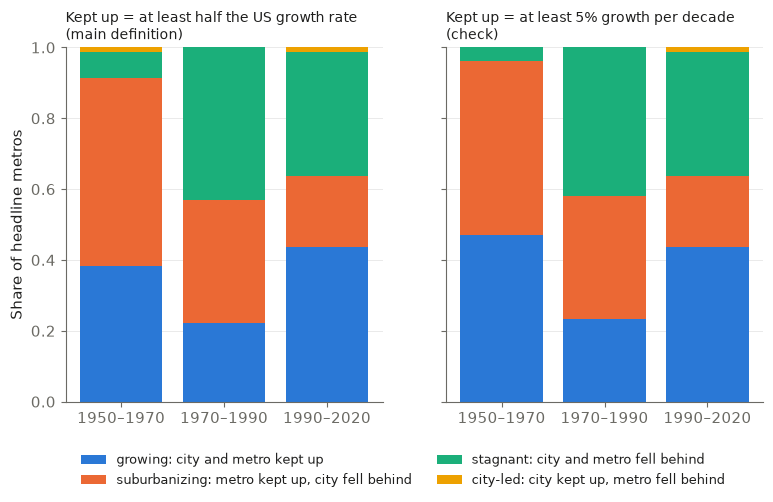

In [4]:
order = ["growing", "suburbanizing", "stagnant", "city-led"]
MEANING = {"growing": "growing: city and metro kept up", "suburbanizing": "suburbanizing: metro kept up, city fell behind",
           "stagnant": "stagnant: city and metro fell behind", "city-led": "city-led: city kept up, metro fell behind"}
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharey=True)
for ax, yardstick in zip(axes, ("relative", "absolute")):
    s = shares.loc[yardstick].reindex(columns=order, fill_value=0).loc[list(label.values())]
    bottom = np.zeros(len(s))
    for i, cls in enumerate(order):
        ax.bar(s.index, s[cls], bottom=bottom, color=SERIES_COLORS[i], label=MEANING[cls])
        bottom += s[cls].to_numpy()
    ax.set_title("Kept up = at least half the US growth rate\n(main definition)" if yardstick == "relative"
                 else "Kept up = at least 5% growth per decade\n(check)", loc="left", fontsize=10)
axes[0].set_ylabel("Share of headline metros")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.1))
save_figure(fig, "rq0a_classes")

## City share of its metro, 1940–2020

PosixPath('/Users/lrubin/Documents/code/US Housing Crisis Analysis/reports/figures/rq0a_city_share.png')

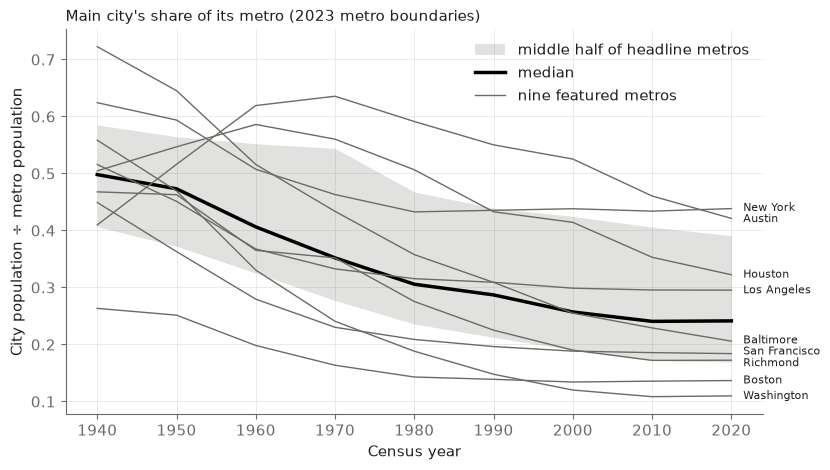

In [5]:
FEATURED = {"35620": "New York", "31080": "Los Angeles", "14460": "Boston", "41860": "San Francisco",
            "47900": "Washington", "12580": "Baltimore", "40060": "Richmond", "26420": "Houston",
            "12420": "Austin"}
share = head[head.year >= 1940].assign(share=lambda d: d.city_population / d.metro_population)
wide = share.pivot(index="year", columns="geo_id", values="share")
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(wide.index, wide.quantile(0.25, axis=1), wide.quantile(0.75, axis=1), color=MUTED, alpha=0.2,
                lw=0, label="middle half of headline metros")
ax.plot(wide.index, wide.median(axis=1), color="black", lw=2.5, label="median")
# end labels spread apart where lines finish close together (San Francisco and Richmond)
label_y = spread_labels([wide[f"cbsa:{code}"].iloc[-1] for code in FEATURED], min_gap=0.02)
for (code, name), y in zip(FEATURED.items(), label_y):
    s = wide[f"cbsa:{code}"]
    ax.plot(s.index, s, color=MUTED, lw=1, label="nine featured metros" if code == "35620" else None)
    ax.annotate(name, (s.index[-1], s.iloc[-1]), xytext=(s.index[-1] + 1.5, y), textcoords="data",
                fontsize=8, va="center")
ax.set(xlabel="Census year", ylabel="City population ÷ metro population")
ax.set_title("Main city's share of its metro (2023 metro boundaries)", loc="left", fontsize=11)
ax.legend(loc="upper right")
save_figure(fig, "rq0a_city_share")

## The three preset answers

Checks that apply: rule 1 — absolute yardstick, bar at ⅓ and ⅔, core = all old cities, central
counties; rule 2 — absolute yardstick, bar at ⅓ and ⅔, annexing threshold 10% and 40%, central
counties; rule 3 — absolute yardstick, bar at ⅓ and ⅔, central counties (plan, Execution notes 9).

In [6]:
VERSIONS = {
    "main": {}, "absolute yardstick": {"yardstick": "absolute"},
    "bar at 1/3 of US growth": {"fraction": 1 / 3}, "bar at 2/3 of US growth": {"fraction": 2 / 3},
    "annexing threshold 10%": {"threshold": 0.10}, "annexing threshold 40%": {"threshold": 0.40},
    "core = all old cities": {"core": True}, "central counties only": {"central": True},
}
APPLIES = {
    "1": ["main", "absolute yardstick", "bar at 1/3 of US growth", "bar at 2/3 of US growth",
          "core = all old cities", "central counties only"],
    "2": ["main", "absolute yardstick", "bar at 1/3 of US growth", "bar at 2/3 of US growth",
          "annexing threshold 10%", "annexing threshold 40%", "central counties only"],
    "3": ["main", "absolute yardstick", "bar at 1/3 of US growth", "bar at 2/3 of US growth",
          "central counties only"],
}
U = {name: cm.units(panel, US, consolidations=consolidations, **kw) for name, kw in VERSIONS.items()}


def row(rule, version, r, n, answer, detail=""):
    return {"rule": rule, "version": version, "estimate": r.estimate, "low": r.low, "high": r.high, "n": n,
            "answer": answer, "detail": detail}


def rule1(u, version):
    r = cm.paired_draws(u, cm.share_metro_kept_up)
    n = int(((u.city_1950 == 0) & u.metro_1950.notna()).sum())
    return [row("1", version, r, n, cm.decide_rule1(r.low, r.high), f"skipped draws: {r.skipped}")]


def rule2(u, version):
    r = cm.paired_draws(u, cm.fall_behind_gap)
    nf, na = cm.rule2_groups(u)
    return [row("2", version, r, nf + na, cm.decide_rule2(r.low, r.high, nf, na),
                f"fixed {nf}, annexing {na}; skipped draws: {r.skipped}")]


def rule3(u, version):
    r2 = cm.paired_draws(u, lambda d: cm.fall_behind_rise(d, 1970))
    r3 = cm.paired_draws(u, lambda d: cm.fall_behind_rise(d, 1990))
    answer = cm.decide_rule3(r2, r3)
    f = ", ".join(f"F({label[s]}) = {cm.fall_behind_share(u, s):.2f}" for s, _ in RQ0A_PERIODS)
    n2 = int((u.metro_1950.notna() & u.metro_1970.notna()).sum())
    n3 = int((u.metro_1950.notna() & u.metro_1990.notna()).sum())
    return [row("3 (F2−F1)", version, r2, n2, answer, f), row("3 (F3−F1)", version, r3, n3, answer, f)]


RULES = {"1": rule1, "2": rule2, "3": rule3}
answers = []
for rule, fn in RULES.items():
    rows_ = [x for v in APPLIES[rule] for x in fn(U[v], v)]
    main = rows_[0]["answer"]
    checks = {x["version"]: x["answer"] for x in rows_ if x["version"] != "main"}
    verdict = cm.robustness(main, checks)
    for x in rows_:
        if x["version"] == "main":
            x["detail"] = f"{verdict}; {x['detail']}"
    answers += rows_

# Context, no rule (spec §4.3)
u = U["main"]
ctx = [row("1", "context: weighted by 1950 city population",
           cm.paired_draws(u, lambda d: cm.share_metro_kept_up(d, weight="city_pop_1950")), "", "")]
for s in (1970, 1990):
    n = int(((u[f"city_{s}"] == 0) & u[f"metro_{s}"].notna()).sum())
    ctx.append(row("1", f"context: S in {label[s]}", cm.paired_draws(u, lambda d, s=s: cm.share_metro_kept_up(d, s)), n, ""))
nf, na = cm.rule2_groups(u, conditioned=False)
ctx.append(row("2", "context: all headline metros (not conditioned)",
               cm.paired_draws(u, lambda d: cm.fall_behind_gap(d, conditioned=False)), nf + na, "",
               f"fixed {nf}, annexing {na}"))
for region, g in u.groupby("region"):
    for s, _ in RQ0A_PERIODS:
        ctx.append(row("3", f"context: F in {label[s]}, {region}",
                       cm.paired_draws(g, lambda d, s=s: cm.fall_behind_share(d, s)), int(g[f"metro_{s}"].notna().sum()), ""))
table = pd.DataFrame(answers + ctx)
table.to_csv(TABLES_DIR / "rq0a_answers.csv", index=False)
table.round(3)

,rule,version,estimate,low,high,n,answer,detail
0,1,main,0.878,0.792,0.955,49,mostly suburbanization,robust; skipped draws: 0
1,1,absolute yardstick,0.930,0.857,0.981,43,mostly suburbanization,skipped draws: 0
2,1,bar at 1/3 of US growth,0.909,0.829,0.977,44,mostly suburbanization,skipped draws: 0
3,1,bar at 2/3 of US growth,0.780,0.681,0.872,50,mostly suburbanization,skipped draws: 0
4,1,core = all old cities,0.878,0.792,0.955,49,mostly suburbanization,skipped draws: 0
5,1,central counties only,0.857,0.767,0.935,49,mostly suburbanization,skipped draws: 0
6,2,main,0.687,0.542,0.816,69,plateau concentrated in fixed-boundary cities,"robust; fixed 33, annexing 36; skipped draws: 0"
7,2,absolute yardstick,0.699,0.548,0.836,73,plateau concentrated in fixed-boundary cities,"fixed 35, annexing 38; skipped draws: 0"
8,2,bar at 1/3 of US growth,0.695,0.543,0.830,72,plateau concentrated in fixed-boundary cities,"fixed 35, annexing 37; skipped draws: 0"
9,2,bar at 2/3 of US growth,0.706,0.552,0.833,64,plateau concentrated in fixed-boundary cities,"fixed 28, annexing 36; skipped draws: 0"


## Finding (run 2026-10-19; rules fixed in the spec before any class was computed)

**Rule 1: mostly suburbanization (robust).** Of the 49 old big cities that fell behind the US in 1950–70, 88% sat in metros that kept up (90% range 79–96%). Every check agrees: absolute yardstick 93%, bar at ⅓ of US growth 91%, at ⅔ 78%, all old cities as the core 88%, central counties only 86%. Weighted by 1950 city population the share is 95%. The pattern did not last: among cities that fell behind in 1970–90 only 44% had a metro that kept up (34–55%), and in 1990–2020 36% (25–49%). Later stalls came with the metro more often than not. ("Suburbanization" is the rule's label for the growth pattern, city behind and metro keeping up; it does not show that people moved out.)

**Rule 2: the 1950–70 plateau is concentrated in fixed-boundary cities (robust).** Among the 69 headline metros that kept up in 1950–70 and whose main city has a known boundary flag (33 fixed-boundary, 36 annexing; 5 unknown, left out), 91% of fixed-boundary cities fell behind against 22% of annexing cities: D = 0.69 (0.54–0.82). The six checks give D from 0.63 to 0.71, all with the same answer; over all headline metros (not conditioned on the metro keeping up) D is 0.66. Part of this is mechanical: people in annexed land count as city growth, which is what "boundary artifact" means. It does not show what a fixed-boundary city would have done with more land; that needs same-boundary populations (option B).

**Rule 3: metros fell behind later, by 1970–90 (robust), and unevenly.** The share of headline metros falling behind the US went from 9% in 1950–70 to 43% in 1970–90 and 36% in 1990–2020: F₂ − F₁ = 0.35 (0.25–0.44), F₃ − F₁ = 0.28 (0.17–0.37). All four checks agree. The rise is a jump in 1970–90 that partly eased after 1990, not a steady climb. It is almost entirely Northeast and Midwest: their share went from 12% to 77% and then 61%, while in the South and West it stayed between 5% and 8%.

**Limits.** Metros use 2023 boundaries, which include counties that were rural in 1950 (the central-counties check gives the same answers). The headline set is the 1950 top 100, many of them at their peak, which raises F₁ and works against "later". Annexing flags rest on land area, with a bracket rule where WP27 drops a city; 5 cities stay unknown. Census coverage changes over time are a few percent, small next to bars of 11–17%.

**For the paper:** Most of the post-1950 stall of America's old big cities was a city-proper pattern: nearly nine in ten of those that fell behind in 1950–70 sat in metros that kept up, and they were overwhelmingly cities whose boundaries didn't grow; whole metros fell behind only from the 1970s, and almost only in the Northeast and Midwest.